In [1]:
# ---- Cell 1: install and login ----
!pip install -q transformers datasets accelerate scikit-learn
  # token stored in Colab Secrets, never in the notebook

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# ---- Cell 2: imports ----
import gc
import os
import warnings

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import Dataset, disable_progress_bar
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)
from transformers.utils import logging as hf_logging
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")
hf_logging.set_verbosity_error()
disable_progress_bar()
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

In [5]:
# ---- Cell 3: configuration ----
SEED = 3407
N_FOLDS = 5
MAX_LENGTH = 256
TEST_FRACTION = 0.15
STOP_FRACTION = 0.10

MODEL_NAME = "FacebookAI/roberta-base"
# Other options: "roberta-base", "microsoft/deberta-v3-base", "mental/mental-roberta-base"

DATA_PATH = "/content/drive/MyDrive/Cognitive Distortion/Annotated_data.csv"
OUTPUT_DIR = "/content/drive/MyDrive/Cognitive Distortion"
RUN_NAME = f"dominant_distortion_{MODEL_NAME.split('/')[-1]}_ce_span"

TEXT_COLUMN = "Distorted part"
LABEL_COLUMN = "Dominant Distortion"

LEARNING_RATE = 3e-5
BATCH_SIZE = 16
CV_EPOCHS = 6
FINAL_EPOCHS = 10

In [6]:
# ---- Cell 4: data, labels, splits ----
raw_df = pd.read_csv(DATA_PATH)
raw_df = raw_df[raw_df[LABEL_COLUMN] != "No Distortion"]
assert TEXT_COLUMN in raw_df.columns and LABEL_COLUMN in raw_df.columns

data_df = raw_df[[TEXT_COLUMN, LABEL_COLUMN]].copy()
data_df = data_df.dropna().reset_index(drop=True)
data_df[LABEL_COLUMN] = data_df[LABEL_COLUMN].astype(str).str.strip()

label_encoder = LabelEncoder()
data_df["label_id"] = label_encoder.fit_transform(data_df[LABEL_COLUMN])
CLASS_NAMES = list(label_encoder.classes_)
NUM_CLASSES = len(CLASS_NAMES)
print(f"Rows: {len(data_df)} | Classes: {NUM_CLASSES}")
print(data_df[LABEL_COLUMN].value_counts())

# Held-out test set, never used for training or model selection
dev_df, test_df = train_test_split(
    data_df, test_size=TEST_FRACTION, stratify=data_df["label_id"], random_state=SEED
)
dev_df = dev_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Final model: 90% train / 10% early-stopping split of the development set
final_train_df, final_stop_df = train_test_split(
    dev_df, test_size=STOP_FRACTION, stratify=dev_df["label_id"], random_state=SEED
)
final_train_df = final_train_df.reset_index(drop=True)
final_stop_df = final_stop_df.reset_index(drop=True)

fold_splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_indices = list(fold_splitter.split(dev_df, dev_df["label_id"]))
print("Development:", len(dev_df), "| Test:", len(test_df))

Rows: 1597 | Classes: 10
Dominant Distortion
Overgeneralization         239
Mind Reading               239
Magnification              195
Labeling                   165
Personalization            153
Fortune-telling            143
Emotional Reasoning        134
Mental filter              122
Should statements          107
All-or-nothing thinking    100
Name: count, dtype: int64
Development: 1357 | Test: 240


### Step 5: Tokenizer and Datasets Preparation

In [7]:
# ---- Cell 5: tokenizer and datasets ----
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Pad token:", tokenizer.pad_token)   # must not be None

KEEP_COLUMNS = ["input_ids", "attention_mask", "labels"]


def build_dataset(df: pd.DataFrame) -> Dataset:
    def tokenize_example(example):
        encoded = tokenizer(
            str(example[TEXT_COLUMN]),
            truncation=True,
            max_length=MAX_LENGTH,
        )
        encoded["labels"] = int(example["label_id"])
        return encoded

    dataset = Dataset.from_pandas(df.reset_index(drop=True))
    dataset = dataset.map(tokenize_example)
    return dataset.remove_columns([c for c in dataset.column_names if c not in KEEP_COLUMNS])


data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

final_train_dataset = build_dataset(final_train_df)
final_stop_dataset = build_dataset(final_stop_df)
test_dataset = build_dataset(test_df)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Pad token: <pad>


### Step 6: Model, Metrics, and Training Configurations

In [8]:
# ---- Cell 6: model, metrics, training arguments (plain cross-entropy) ----
def build_model():
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_CLASSES
    )


def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    predictions = logits.argmax(axis=1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro", zero_division=0),
        "weighted_f1": f1_score(labels, predictions, average="weighted", zero_division=0),
    }


def make_training_args(output_dir, num_epochs):
    return TrainingArguments(
        output_dir=output_dir,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=32,
        num_train_epochs=num_epochs,
        weight_decay=0.01,
        lr_scheduler_type="linear",
        optim="adamw_torch",
        fp16=torch.cuda.is_available(),
        logging_steps=20,
        save_strategy="epoch",
        eval_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="eval_macro_f1",
        greater_is_better=True,
        save_total_limit=1,
        seed=SEED,
        report_to="none",
    )

In [9]:
# ---- Cell 7: 5-fold cross-validation ----
fold_results = []

for fold, (train_indices, val_indices) in enumerate(fold_indices):
    set_seed(SEED)
    fold_train_dataset = build_dataset(dev_df.iloc[train_indices])
    fold_val_dataset = build_dataset(dev_df.iloc[val_indices])

    model = build_model()
    trainer = Trainer(
        model=model,
        args=make_training_args(f"./results_fold{fold}", CV_EPOCHS),
        train_dataset=fold_train_dataset,
        eval_dataset=fold_val_dataset,
        compute_metrics=compute_metrics,
        data_collator=data_collator,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2, early_stopping_threshold=0.005)],
    )
    trainer.train()

    metrics = trainer.evaluate()
    metrics["fold"] = fold
    fold_results.append(metrics)
    print(f"Fold {fold}: acc {metrics['eval_accuracy']:.4f} | macro F1 {metrics['eval_macro_f1']:.4f}")

    del model, trainer, fold_train_dataset, fold_val_dataset
    gc.collect()
    torch.cuda.empty_cache()

cv_results_df = pd.DataFrame(fold_results)
print(cv_results_df[["fold", "eval_accuracy", "eval_macro_f1", "eval_weighted_f1"]])
for name in ["eval_accuracy", "eval_macro_f1", "eval_weighted_f1"]:
    print(f"{name:18s} {cv_results_df[name].mean():.4f} +/- {cv_results_df[name].std():.4f}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '2.275', 'grad_norm': '4.151', 'learning_rate': '2.86e-05', 'epoch': '0.2941'}
{'loss': '2.281', 'grad_norm': '4.488', 'learning_rate': '2.713e-05', 'epoch': '0.5882'}
{'loss': '2.25', 'grad_norm': '3.51', 'learning_rate': '2.574e-05', 'epoch': '0.8824'}
{'eval_loss': '2.158', 'eval_accuracy': '0.2316', 'eval_macro_f1': '0.08643', 'eval_weighted_f1': '0.1258', 'eval_runtime': '0.3266', 'eval_samples_per_second': '832.7', 'eval_steps_per_second': '27.55', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '2.072', 'grad_norm': '11.31', 'learning_rate': '2.426e-05', 'epoch': '1.176'}
{'loss': '1.969', 'grad_norm': '8.466', 'learning_rate': '2.279e-05', 'epoch': '1.471'}
{'loss': '1.882', 'grad_norm': '16.49', 'learning_rate': '2.132e-05', 'epoch': '1.765'}
{'eval_loss': '1.91', 'eval_accuracy': '0.3456', 'eval_macro_f1': '0.2702', 'eval_weighted_f1': '0.2946', 'eval_runtime': '0.323', 'eval_samples_per_second': '842.1', 'eval_steps_per_second': '27.86', 'epoch': '2'}


... (62 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.7982', 'grad_norm': '14.18', 'learning_rate': '3.75e-06', 'epoch': '5.294'}
{'loss': '0.7136', 'grad_norm': '12.62', 'learning_rate': '2.279e-06', 'epoch': '5.588'}
{'loss': '0.763', 'grad_norm': '19.82', 'learning_rate': '8.088e-07', 'epoch': '5.882'}
{'eval_loss': '1.654', 'eval_accuracy': '0.4649', 'eval_macro_f1': '0.4243', 'eval_weighted_f1': '0.45', 'eval_runtime': '0.3598', 'eval_samples_per_second': '753.3', 'eval_steps_per_second': '25.02', 'epoch': '6'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '66.87', 'train_samples_per_second': '97.45', 'train_steps_per_second': '6.102', 'train_loss': '1.49', 'epoch': '6'}
{'eval_loss': '1.635', 'eval_accuracy': '0.4649', 'eval_macro_f1': '0.4333', 'eval_weighted_f1': '0.4527', 'eval_runtime': '0.3206', 'eval_samples_per_second': '845.4', 'eval_steps_per_second': '28.08', 'epoch': '6'}
Fold 4: acc 0.4649 | macro F1 0.4333
   fold  eval_accuracy  eval_macro_f1  eval_weighted_f1
0     0       0.389706       0.347677          0.375745
1     1       0.466912       0.424743          0.453253
2     2       0.431734       0.402854          0.429006
3     3       0.420664       0.420376          0.420344
4     4       0.464945       0.433274          0.452661
eval_accuracy      0.4348 +/- 0.0323
eval_macro_f1      0.4058 +/- 0.0343
eval_weighted_f1   0.4262 +/- 0.0317


In [10]:
# ---- Cell 8: final model ----
set_seed(SEED)
final_model = build_model()
final_trainer = Trainer(
    model=final_model,
    args=make_training_args("./results_final", FINAL_EPOCHS),
    train_dataset=final_train_dataset,
    eval_dataset=final_stop_dataset,
    compute_metrics=compute_metrics,
    data_collator=data_collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2, early_stopping_threshold=0.005)],
)
final_trainer.train()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '2.272', 'grad_norm': '2.107', 'learning_rate': '2.926e-05', 'epoch': '0.2597'}
{'loss': '2.288', 'grad_norm': '4.046', 'learning_rate': '2.852e-05', 'epoch': '0.5195'}
{'loss': '2.231', 'grad_norm': '5.808', 'learning_rate': '2.774e-05', 'epoch': '0.7792'}
{'eval_loss': '2.091', 'eval_accuracy': '0.2647', 'eval_macro_f1': '0.1111', 'eval_weighted_f1': '0.158', 'eval_runtime': '0.1579', 'eval_samples_per_second': '861.5', 'eval_steps_per_second': '31.67', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '2.219', 'grad_norm': '6.12', 'learning_rate': '2.696e-05', 'epoch': '1.039'}
{'loss': '2.084', 'grad_norm': '9.946', 'learning_rate': '2.618e-05', 'epoch': '1.299'}
{'loss': '1.944', 'grad_norm': '9.817', 'learning_rate': '2.54e-05', 'epoch': '1.558'}
{'loss': '1.852', 'grad_norm': '12.48', 'learning_rate': '2.462e-05', 'epoch': '1.818'}
{'eval_loss': '1.782', 'eval_accuracy': '0.4265', 'eval_macro_f1': '0.3396', 'eval_weighted_f1': '0.3762', 'eval_runtime': '0.1563', 'eval_samples_per_second': '870.1', 'eval_steps_per_second': '31.99', 'epoch': '2'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '1.85', 'grad_norm': '15.89', 'learning_rate': '2.384e-05', 'epoch': '2.078'}
{'loss': '1.616', 'grad_norm': '19.73', 'learning_rate': '2.306e-05', 'epoch': '2.338'}
{'loss': '1.479', 'grad_norm': '11.93', 'learning_rate': '2.229e-05', 'epoch': '2.597'}
{'loss': '1.469', 'grad_norm': '14.46', 'learning_rate': '2.151e-05', 'epoch': '2.857'}
{'eval_loss': '1.586', 'eval_accuracy': '0.4485', 'eval_macro_f1': '0.3735', 'eval_weighted_f1': '0.4128', 'eval_runtime': '0.1517', 'eval_samples_per_second': '896.4', 'eval_steps_per_second': '32.95', 'epoch': '3'}


... (9 outputs left out)

{'loss': '0.3222', 'grad_norm': '16.32', 'learning_rate': '9.117e-06', 'epoch': '7.013'}
{'loss': '0.2194', 'grad_norm': '5.678', 'learning_rate': '8.338e-06', 'epoch': '7.273'}
{'loss': '0.1414', 'grad_norm': '3.372', 'learning_rate': '7.558e-06', 'epoch': '7.532'}
{'loss': '0.2329', 'grad_norm': '8.692', 'learning_rate': '6.779e-06', 'epoch': '7.792'}
{'eval_loss': '1.924', 'eval_accuracy': '0.4779', 'eval_macro_f1': '0.455', 'eval_weighted_f1': '0.4744', 'eval_runtime': '0.1531', 'eval_samples_per_second': '888.6', 'eval_steps_per_second': '32.67', 'epoch': '8'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '89.89', 'train_samples_per_second': '135.8', 'train_steps_per_second': '8.566', 'train_loss': '1.079', 'epoch': '8'}


TrainOutput(global_step=616, training_loss=1.0794865005202108, metrics={'train_runtime': 89.8851, 'train_samples_per_second': 135.84, 'train_steps_per_second': 8.566, 'train_loss': 1.0794865005202108, 'epoch': 8.0})

Test accuracy:    0.4208
Test macro F1:    0.4044
Test weighted F1: 0.4228

                         precision    recall  f1-score   support

All-or-nothing thinking       0.30      0.40      0.34        15
    Emotional Reasoning       0.17      0.25      0.20        20
        Fortune-telling       0.48      0.50      0.49        22
               Labeling       0.56      0.40      0.47        25
          Magnification       0.34      0.41      0.38        29
          Mental filter       0.20      0.17      0.18        18
           Mind Reading       0.63      0.67      0.65        36
     Overgeneralization       0.55      0.31      0.39        36
        Personalization       0.45      0.43      0.44        23
      Should statements       0.45      0.56      0.50        16

               accuracy                           0.42       240
              macro avg       0.41      0.41      0.40       240
           weighted avg       0.44      0.42      0.42       240



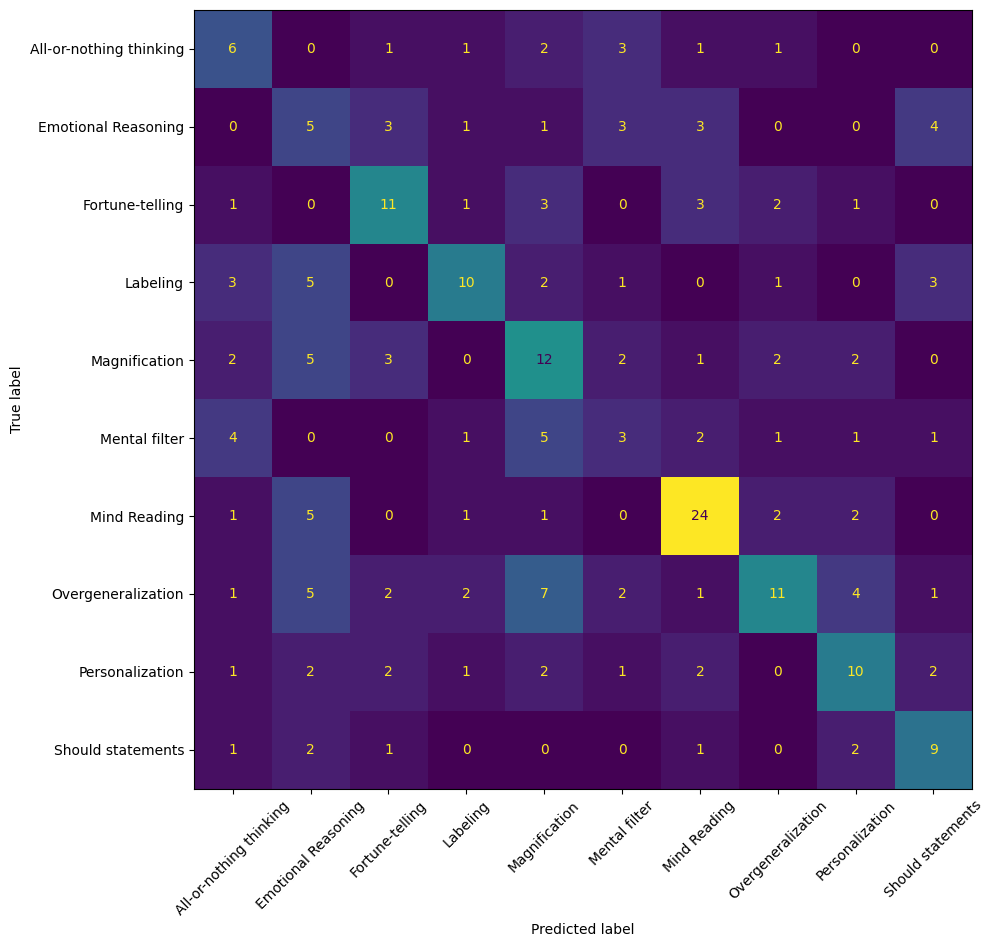

Saved predictions.


In [11]:
# ---- Cell 9: test evaluation, confusion matrix, saved predictions ----
test_output = final_trainer.predict(test_dataset)
predicted_ids = np.argmax(test_output.predictions, axis=1)
true_ids = test_output.label_ids

print(f"Test accuracy:    {accuracy_score(true_ids, predicted_ids):.4f}")
print(f"Test macro F1:    {f1_score(true_ids, predicted_ids, average='macro', zero_division=0):.4f}")
print(f"Test weighted F1: {f1_score(true_ids, predicted_ids, average='weighted', zero_division=0):.4f}\n")
print(classification_report(true_ids, predicted_ids, labels=list(range(NUM_CLASSES)),
                            target_names=CLASS_NAMES, zero_division=0))

matrix = confusion_matrix(true_ids, predicted_ids, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()

predictions_df = pd.DataFrame({
    "text": test_df[TEXT_COLUMN].values,
    "actual": label_encoder.inverse_transform(true_ids),
    "predicted": label_encoder.inverse_transform(predicted_ids),
})
predictions_df.to_csv(f"{OUTPUT_DIR}/{RUN_NAME}_predictions.csv", index=False)
print("Saved predictions.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

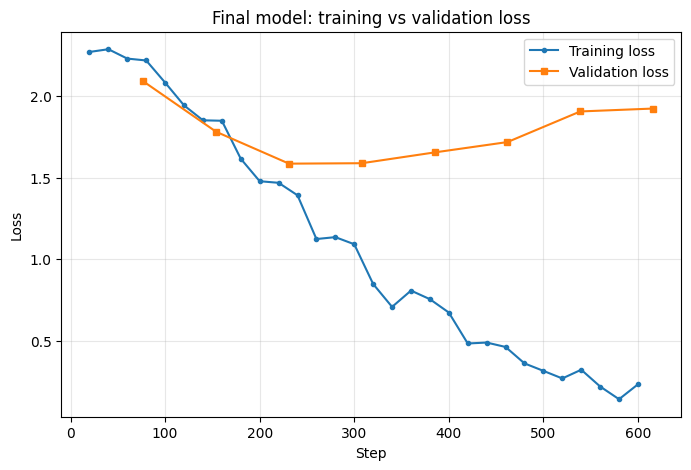

In [12]:
# ---- Cell 10: save the model and plot the loss curve ----
final_model.save_pretrained(f"{OUTPUT_DIR}/{RUN_NAME}_model")
tokenizer.save_pretrained(f"{OUTPUT_DIR}/{RUN_NAME}_tokenizer")

history = final_trainer.state.log_history
train_points = [(h["step"], h["loss"]) for h in history if "loss" in h and "eval_loss" not in h]
eval_points = [(h["step"], h["eval_loss"]) for h in history if "eval_loss" in h]

plt.figure(figsize=(8, 5))
plt.plot(*zip(*train_points), label="Training loss", marker="o", markersize=3)
plt.plot(*zip(*eval_points), label="Validation loss", marker="s", markersize=4)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Final model: training vs validation loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()